In [1]:
import matplotlib.pyplot as plt
import numpy as np

from fundamentos_procesamiento_imagenes.tarea_2.pregunta_1.procesamiento import base_image, gaussian_fiilter, rmse, \
    rmse_curve, spatial_adaptive_filter

image, noise_image, square_mask, circle_mask, background_mask = base_image()

In [2]:
# Analisis de diferentes sigmas

sigmas = np.concatenate((
    [0.0],
    np.arange(0.20, 4.01, 0.05)
))

rmse_global, min_global, sigma_minimo_global = rmse_curve(image, noise_image, None, sigmas)
rmse_background, min_background, sigma_minimo_background = rmse_curve(image, noise_image, background_mask, sigmas)
rmse_square, min_square, sigma_minimo_square = rmse_curve(image, noise_image, square_mask, sigmas)
rmse_circle, min_circle, sigma_minimo_circle = rmse_curve(image, noise_image, circle_mask, sigmas)

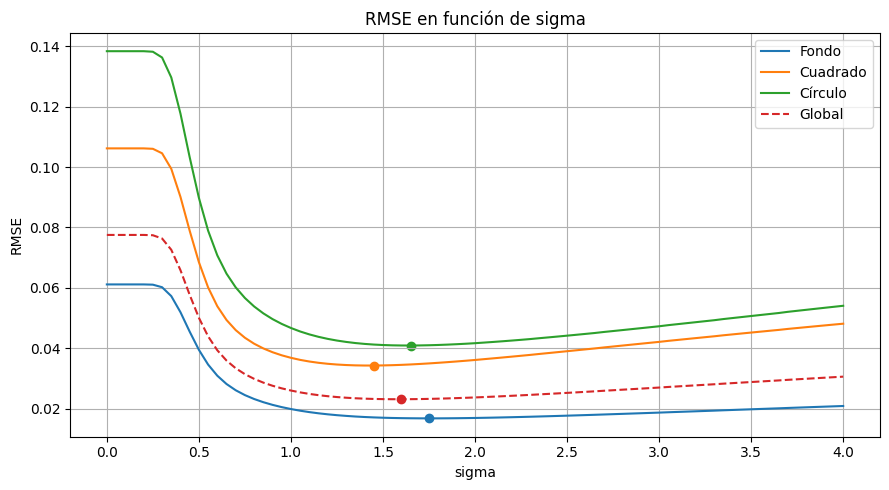

In [3]:
#Graficar curvas

plt.figure(figsize=(9,5))

plt.plot(
    sigmas,
    rmse_background,
    label="Fondo"
)

plt.plot(
    sigmas,
    rmse_square,
    label="Cuadrado"
)

plt.plot(
    sigmas,
    rmse_circle,
    label="Círculo"
)

plt.plot(
    sigmas,
    rmse_global,
    "--",
    label="Global"
)

plt.scatter(
    sigma_minimo_background,
    rmse_background[min_background]
)

plt.scatter(
    sigma_minimo_square,
    rmse_square[min_square]
)

plt.scatter(
    sigma_minimo_circle,
    rmse_circle[min_circle]
)

plt.scatter(
    sigma_minimo_global,
    rmse_global[min_global]
)

plt.xlabel("sigma")
plt.ylabel("RMSE")
plt.title("RMSE en función de sigma")
plt.grid()
plt.legend()

plt.tight_layout()
plt.show()

RMSE global filtro adaptativo: 0.0185
RMSE global mejor sigma: 0.0231
RMSE cuadrado filtro adaptativo: 0.0286
RMSE cuadrado mejor sigma: 0.0345
RMSE círculo filtro adaptativo: 0.0323
RMSE círculo mejor sigma: 0.0409
RMSE fondo filtro adaptativo: 0.0129
RMSE fondo mejor sigma: 0.0168


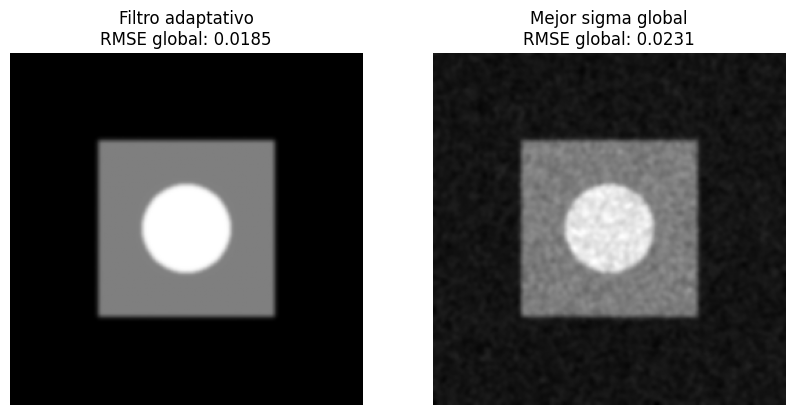

In [8]:
# Funcion F(u)

intensidades = np.array([0.15, 0.45, 0.80])
sigmas_optimos = np.array([
    sigma_minimo_background,
    sigma_minimo_square,
    sigma_minimo_circle
])

imagen_filtro_adaptativo = spatial_adaptive_filter(image, noise_image, intensidades, sigmas_optimos)
imagen_mejor_global = gaussian_fiilter(noise_image, sigma_minimo_global)

rmse_global_adaptativo = rmse(image, imagen_filtro_adaptativo)
rmse_global_mejor = rmse(image, imagen_mejor_global)

rmse_square_adaptativo = rmse(image, imagen_filtro_adaptativo, square_mask)
rmse_square_mejor = rmse(image, imagen_mejor_global, square_mask)

rmse_circle_adaptativo = rmse(image, imagen_filtro_adaptativo, circle_mask)
rmse_circle_mejor = rmse(image, imagen_mejor_global, circle_mask)

rmse_background_adaptativo = rmse(image, imagen_filtro_adaptativo, background_mask)
rmse_background_mejor = rmse(image, imagen_mejor_global, background_mask)

print(f"RMSE global filtro adaptativo: {rmse_global_adaptativo:.4f}")
print(f"RMSE global mejor sigma: {rmse_global_mejor:.4f}")
print(f"RMSE cuadrado filtro adaptativo: {rmse_square_adaptativo:.4f}")
print(f"RMSE cuadrado mejor sigma: {rmse_square_mejor:.4f}")
print(f"RMSE círculo filtro adaptativo: {rmse_circle_adaptativo:.4f}")
print(f"RMSE círculo mejor sigma: {rmse_circle_mejor:.4f}")
print(f"RMSE fondo filtro adaptativo: {rmse_background_adaptativo:.4f}")
print(f"RMSE fondo mejor sigma: {rmse_background_mejor:.4f}")

plt.figure(figsize=(10,5))

# Plot both images
plt.subplot(1, 2, 1)
plt.imshow(imagen_filtro_adaptativo, cmap='gray')
plt.title(f"Filtro adaptativo\nRMSE global: {rmse_global_adaptativo:.4f}")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(imagen_mejor_global, cmap='gray')
plt.title(f"Mejor sigma global\nRMSE global: {rmse_global_mejor:.4f}")
plt.axis('off')

plt.show()